# Connect 4 LED Tile CNN Training

This notebook trains a small CNN to classify individual LED tiles (32x32 pixels) into 3 classes:
- **0** = Empty (off)
- **1** = Red (Player 1)
- **2** = Blue (Player 2/AI)

The trained model will be exported for use on ESP32.

## Setup & Install Dependencies

In [1]:
# Install dependencies
!pip install -q tensorflow scikit-learn pillow matplotlib

import os
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
import random

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {tf.config.list_physical_devices('GPU')}")

TensorFlow version: 2.13.0
GPU available: []


## Load and Prepare Dataset

In [6]:
# Configuration
TILE_SIZE = 32  # Size to resize tiles to
NUM_CLASSES = 3
LABELS_FILE = 'tile_labels_shifted.json'
IMAGES_DIR = 'led_dataset/photos'  # Adjust if your images are elsewhere

# Load labels
with open(LABELS_FILE, 'r') as f:
    labels_dict = json.load(f)

print(f"Total labeled tiles: {len(labels_dict)}")

# Count per class
class_counts = {0: 0, 1: 0, 2: 0}
for v in labels_dict.values():
    class_counts[int(v)] += 1

print(f"\nClass distribution:")
print(f"  Empty (0): {class_counts[0]}")
print(f"  Red (1):   {class_counts[1]}")
print(f"  Blue (2):  {class_counts[2]}")

Total labeled tiles: 9536

Class distribution:
  Empty (0): 4864
  Red (1):   2342
  Blue (2):  2330


In [7]:
def load_tile_dataset(images_dir, labels_dict, tile_size=32):
    """
    Load tile images and labels.
    Returns X (images), y (labels), filenames
    """
    X_list = []
    y_list = []
    filenames = []
    missing = 0
    
    for fname, label in labels_dict.items():
        # Handle Windows-style paths
        fname_clean = fname.replace('\\', '/')
        
        # Try different path combinations
        possible_paths = [
            Path(fname_clean),
            Path(images_dir) / Path(fname_clean).name,
            Path(fname_clean.split('/')[-1]),
        ]
        
        img_path = None
        for p in possible_paths:
            if p.exists():
                img_path = p
                break
        
        if img_path is None:
            missing += 1
            continue
        
        try:
            img = Image.open(img_path).convert('RGB')
            img = img.resize((tile_size, tile_size), Image.BILINEAR)
            arr = np.array(img, dtype=np.float32) / 255.0
            
            X_list.append(arr)
            y_list.append(int(label))
            filenames.append(str(img_path))
        except Exception as e:
            print(f"Error loading {img_path}: {e}")
            missing += 1
    
    if missing > 0:
        print(f"Warning: {missing} images not found")
    
    X = np.stack(X_list, axis=0)
    y = np.array(y_list, dtype=np.int32)
    
    return X, y, filenames

# Load dataset
print("Loading dataset...")
X, y, filenames = load_tile_dataset(IMAGES_DIR, labels_dict, TILE_SIZE)
print(f"\nLoaded {len(X)} tile images")
print(f"Shape: {X.shape}")
print(f"Labels shape: {y.shape}")

Loading dataset...

Loaded 9536 tile images
Shape: (9536, 32, 32, 3)
Labels shape: (9536,)


## 4️⃣ Visualize Sample Tiles

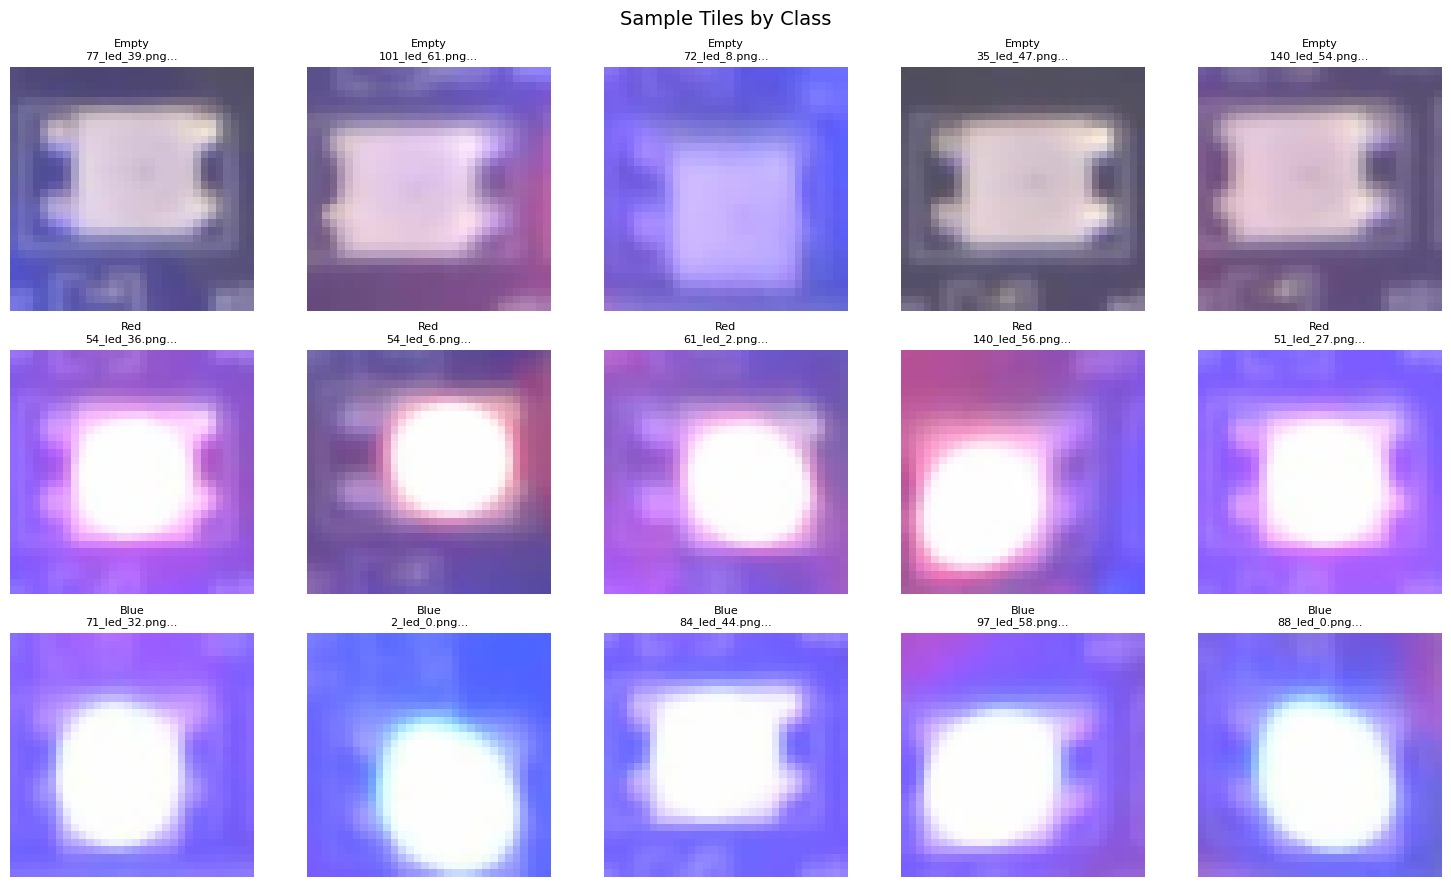

In [8]:
def show_sample_tiles(X, y, filenames, n_per_class=5):
    """Show sample tiles from each class"""
    class_names = ['Empty', 'Red', 'Blue']
    
    fig, axes = plt.subplots(3, n_per_class, figsize=(15, 9))
    
    for cls in range(3):
        # Get indices for this class
        indices = np.where(y == cls)[0]
        # Random sample
        sample_idx = np.random.choice(indices, min(n_per_class, len(indices)), replace=False)
        
        for i, idx in enumerate(sample_idx):
            axes[cls, i].imshow(X[idx])
            axes[cls, i].set_title(f"{class_names[cls]}\n{Path(filenames[idx]).name[:20]}...", fontsize=8)
            axes[cls, i].axis('off')
    
    plt.suptitle('Sample Tiles by Class', fontsize=14)
    plt.tight_layout()
    plt.show()

show_sample_tiles(X, y, filenames)

## 5️⃣ Create the CNN Model

In [9]:
def create_tile_model(input_shape=(32, 32, 3), num_classes=3):
    """
    Small CNN optimized for LED tile classification.
    Designed to be small enough for ESP32.
    """
    inp = keras.Input(shape=input_shape)
    
    # Block 1
    x = layers.Conv2D(16, 3, strides=1, padding='same', activation='relu')(inp)
    x = layers.MaxPool2D(2)(x)  # 16x16
    
    # Block 2
    x = layers.Conv2D(32, 3, padding='same', activation='relu')(x)
    x = layers.MaxPool2D(2)(x)  # 8x8
    
    # Block 3 - Depthwise separable conv (efficient)
    x = layers.DepthwiseConv2D(3, padding='same')(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(64, 1, padding='same', activation='relu')(x)
    
    # Global pooling instead of flatten (smaller)
    x = layers.GlobalAveragePooling2D()(x)
    
    # Dense layers
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(num_classes, activation='softmax')(x)
    
    model = keras.Model(inp, out, name='tile_cnn')
    return model

# Create and compile model
model = create_tile_model(input_shape=(TILE_SIZE, TILE_SIZE, 3), num_classes=NUM_CLASSES)
model.summary()

# Count parameters
total_params = model.count_params()
print(f"\nTotal parameters: {total_params:,}")
print(f"Estimated model size: {total_params * 4 / 1024:.1f} KB (float32)")
print(f"Estimated quantized size: {total_params / 1024:.1f} KB (int8)")

Model: "tile_cnn"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 32, 32, 3)]       0         
                                                                 
 conv2d (Conv2D)             (None, 32, 32, 16)        448       
                                                                 
 max_pooling2d (MaxPooling2  (None, 16, 16, 16)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 16, 16, 32)        4640      
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 8, 8, 32)          0         
 g2D)                                                            
                                                                 
 depthwise_conv2d (Depthwis  (None, 8, 8, 32)          320

## 6️⃣ Train the Model

In [10]:
# Split data
X_train, X_val, y_train, y_val, files_train, files_val = train_test_split(
    X, y, filenames, test_size=0.15, random_state=42, stratify=y
)

print(f"Training samples: {len(X_train)}")
print(f"Validation samples: {len(X_val)}")

# Data augmentation for training
data_augmentation = keras.Sequential([
    layers.RandomBrightness(0.2),
    layers.RandomContrast(0.2),
], name='augmentation')

# Apply augmentation to training data
def augment_batch(images, labels):
    return data_augmentation(images, training=True), labels

Training samples: 8105
Validation samples: 1431


In [11]:
# Compile model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Callbacks
callbacks = [
    keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=5, verbose=1),
]

# Train
print("\nTraining...")
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=64,
    callbacks=callbacks,
    verbose=1
)


Training...
Epoch 1/50
127/127 [==============================] - 3s 17ms/step - loss: 0.9105 - accuracy: 0.5778 - val_loss: 0.6672 - val_accuracy: 0.7058 - lr: 0.0010
Epoch 2/50
127/127 [==============================] - 2s 16ms/step - loss: 0.5223 - accuracy: 0.7940 - val_loss: 0.2305 - val_accuracy: 0.9392 - lr: 0.0010
Epoch 3/50
127/127 [==============================] - 2s 16ms/step - loss: 0.2260 - accuracy: 0.9160 - val_loss: 0.1923 - val_accuracy: 0.9175 - lr: 0.0010
Epoch 4/50
127/127 [==============================] - 2s 16ms/step - loss: 0.1565 - accuracy: 0.9446 - val_loss: 0.0840 - val_accuracy: 0.9720 - lr: 0.0010
Epoch 5/50
127/127 [==============================] - 2s 16ms/step - loss: 0.1132 - accuracy: 0.9609 - val_loss: 0.0613 - val_accuracy: 0.9797 - lr: 0.0010
Epoch 6/50
127/127 [==============================] - 2s 15ms/step - loss: 0.0923 - accuracy: 0.9667 - val_loss: 0.0622 - val_accuracy: 0.9811 - lr: 0.0010
Epoch 7/50
127/127 [==============================]

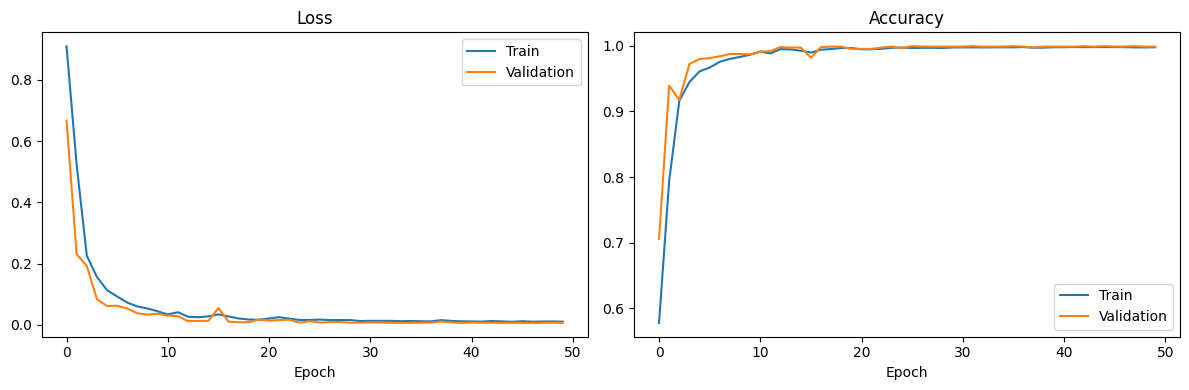

In [12]:
# Plot training history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history.history['loss'], label='Train')
ax1.plot(history.history['val_loss'], label='Validation')
ax1.set_title('Loss')
ax1.set_xlabel('Epoch')
ax1.legend()

ax2.plot(history.history['accuracy'], label='Train')
ax2.plot(history.history['val_accuracy'], label='Validation')
ax2.set_title('Accuracy')
ax2.set_xlabel('Epoch')
ax2.legend()

plt.tight_layout()
plt.show()

## 7️⃣ Evaluate Model

In [13]:
# Evaluate
val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
print(f"Validation Accuracy: {val_acc*100:.2f}%")
print(f"Validation Loss: {val_loss:.4f}")

# Per-class accuracy
y_pred = np.argmax(model.predict(X_val, verbose=0), axis=-1)

class_names = ['Empty', 'Red', 'Blue']
print("\nPer-class accuracy:")
for cls in range(3):
    mask = y_val == cls
    if mask.sum() > 0:
        acc = (y_pred[mask] == cls).mean() * 100
        print(f"  {class_names[cls]}: {acc:.1f}% ({mask.sum()} samples)")

Validation Accuracy: 99.86%
Validation Loss: 0.0065

Per-class accuracy:
  Empty: 99.7% (730 samples)
  Red: 100.0% (351 samples)
  Blue: 100.0% (350 samples)


In [15]:
# Confusion matrix
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

print("\nClassification Report:")
print(classification_report(y_val, y_pred, target_names=class_names))

ModuleNotFoundError: No module named 'seaborn'

## 8️⃣ Verify Predictions - Visual Comparison

This section shows you the tile image alongside its true label and predicted label.

Random samples from validation set:


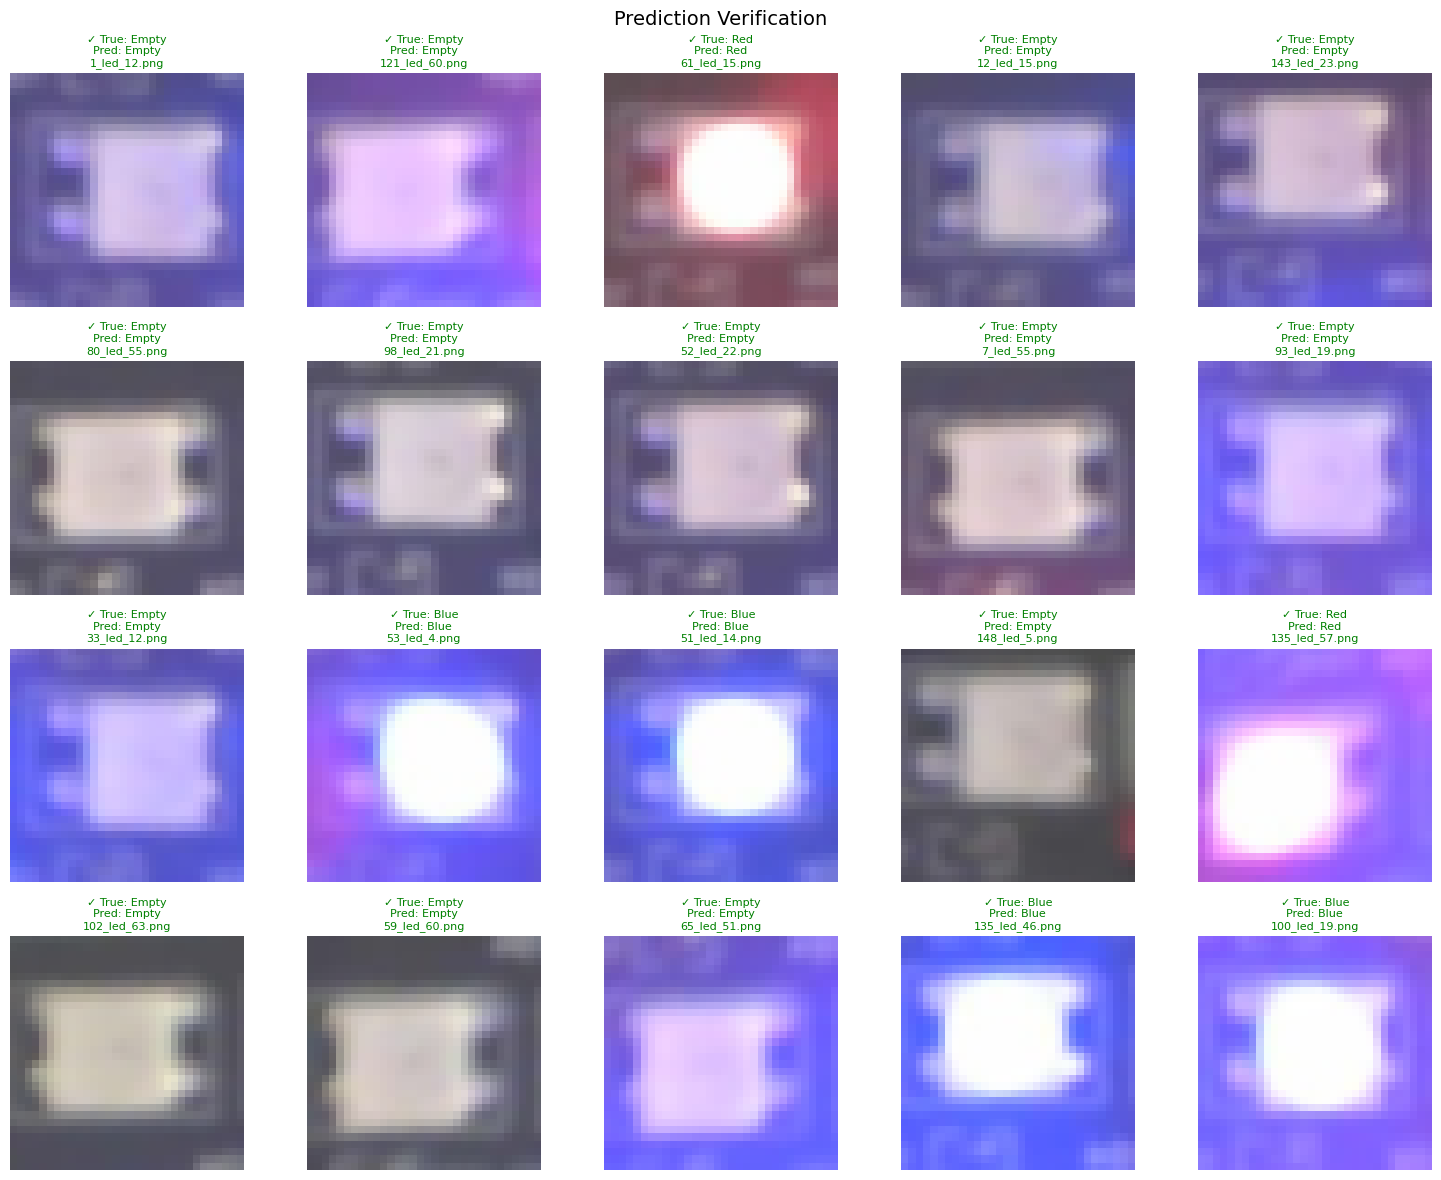

In [16]:
def verify_predictions(X, y_true, y_pred, filenames, n_samples=20, show_errors_only=False):
    """
    Display tiles with true vs predicted labels for verification.
    """
    class_names = ['Empty', 'Red', 'Blue']
    class_colors = ['gray', 'red', 'blue']
    
    if show_errors_only:
        # Get misclassified indices
        indices = np.where(y_true != y_pred)[0]
        title = "Misclassified Tiles"
    else:
        indices = np.arange(len(y_true))
        title = "Prediction Verification"
    
    if len(indices) == 0:
        print("No samples to show!")
        return
    
    # Random sample
    sample_indices = np.random.choice(indices, min(n_samples, len(indices)), replace=False)
    
    n_cols = 5
    n_rows = (len(sample_indices) + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3*n_rows))
    axes = axes.flatten() if n_rows > 1 else [axes] if n_cols == 1 else axes.flatten()
    
    for i, idx in enumerate(sample_indices):
        ax = axes[i]
        ax.imshow(X[idx])
        
        true_label = y_true[idx]
        pred_label = y_pred[idx]
        correct = true_label == pred_label
        
        # Color code: green for correct, red for wrong
        color = 'green' if correct else 'red'
        status = '✓' if correct else '✗'
        
        fname = Path(filenames[idx]).name
        ax.set_title(f"{status} True: {class_names[true_label]}\nPred: {class_names[pred_label]}\n{fname[:25]}", 
                     fontsize=8, color=color)
        ax.axis('off')
    
    # Hide unused axes
    for i in range(len(sample_indices), len(axes)):
        axes[i].axis('off')
    
    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

# Verify random samples
print("Random samples from validation set:")
verify_predictions(X_val, y_val, y_pred, files_val, n_samples=20, show_errors_only=False)

## 9️⃣ Test on a Full Board Image

Upload a full board image and see how the model predicts all 64 tiles.

In [18]:
def split_board_to_tiles(pil_img, tile_size=32):
    """
    Split a full-board PIL image into 8x8 tiles.
    Returns list of PIL tiles in the ordering:
      columns right -> left, rows bottom -> top (index 0 = bottom-right).
    """
    img_w, img_h = pil_img.size
    tw = img_w / 8.0
    th = img_h / 8.0

    tiles = []
    tile_positions = []  # (col, row) for each tile
    
    # columns: right (7) down to 0
    for col in range(7, -1, -1):
        # rows bottom (7) up to 0
        for row in range(7, -1, -1):
            left = int(round(col * tw))
            right = int(round((col + 1) * tw))
            top = int(round(row * th))
            bottom = int(round((row + 1) * th))
            
            tile = pil_img.crop((left, top, right, bottom))
            tile = tile.resize((tile_size, tile_size), Image.BILINEAR)
            tiles.append(tile)
            tile_positions.append((col, row))
    
    return tiles, tile_positions

def predict_full_board(model, board_img_path, tile_size=32):
    """
    Predict the state of all 64 tiles in a full board image.
    Returns the 64-element prediction array.
    """
    img = Image.open(board_img_path).convert('RGB')
    tiles, positions = split_board_to_tiles(img, tile_size=tile_size)
    
    # Prepare batch
    X = np.stack([np.array(t, dtype=np.float32) / 255.0 for t in tiles], axis=0)
    
    # Predict
    preds = model.predict(X, verbose=0)
    pred_classes = np.argmax(preds, axis=-1)
    confidences = np.max(preds, axis=-1)
    
    return pred_classes, confidences, tiles, positions

def visualize_board_prediction(board_img_path, model, tile_size=32, true_labels=None):
    """
    Visualize predictions for a full board.
    """
    pred_classes, confidences, tiles, positions = predict_full_board(model, board_img_path, tile_size)
    
    class_names = ['Empty', 'Red', 'Blue']
    symbols = {0: '.', 1: 'R', 2: 'B'}
    colors = {0: 'white', 1: 'red', 2: 'blue'}
    
    # Show original image
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    
    img = Image.open(board_img_path)
    axes[0].imshow(img)
    axes[0].set_title('Original Board Image')
    axes[0].axis('off')
    
    # Create 8x8 grid visualization
    grid = np.zeros((8, 8), dtype=int)
    for idx, (col, row) in enumerate(positions):
        # Map to grid position
        grid[row, col] = pred_classes[idx]
    
    # Create colored grid
    color_grid = np.zeros((8, 8, 3))
    for r in range(8):
        for c in range(8):
            pred = grid[r, c]
            if pred == 0:
                color_grid[r, c] = [0.2, 0.2, 0.2]  # dark gray
            elif pred == 1:
                color_grid[r, c] = [1, 0, 0]  # red
            else:
                color_grid[r, c] = [0, 0, 1]  # blue
    
    axes[1].imshow(color_grid)
    axes[1].set_title('Predicted Board State')
    
    # Add text labels
    for r in range(8):
        for c in range(8):
            axes[1].text(c, r, symbols[grid[r, c]], ha='center', va='center', 
                        fontsize=16, color='white', fontweight='bold')
    
    axes[1].set_xticks(range(8))
    axes[1].set_yticks(range(8))
    axes[1].set_xlabel('Column')
    axes[1].set_ylabel('Row')
    
    plt.tight_layout()
    plt.show()
    
    # Print the 64-element array
    print("\nPredicted 64-element array:")
    print(list(pred_classes))
    
    # Print grid format
    print("\nGrid format (row 0 = top):")
    for r in range(8):
        row_str = ' '.join(symbols[grid[r, c]] for c in range(8))
        print(f"Row {r}: {row_str}")
    
    return pred_classes

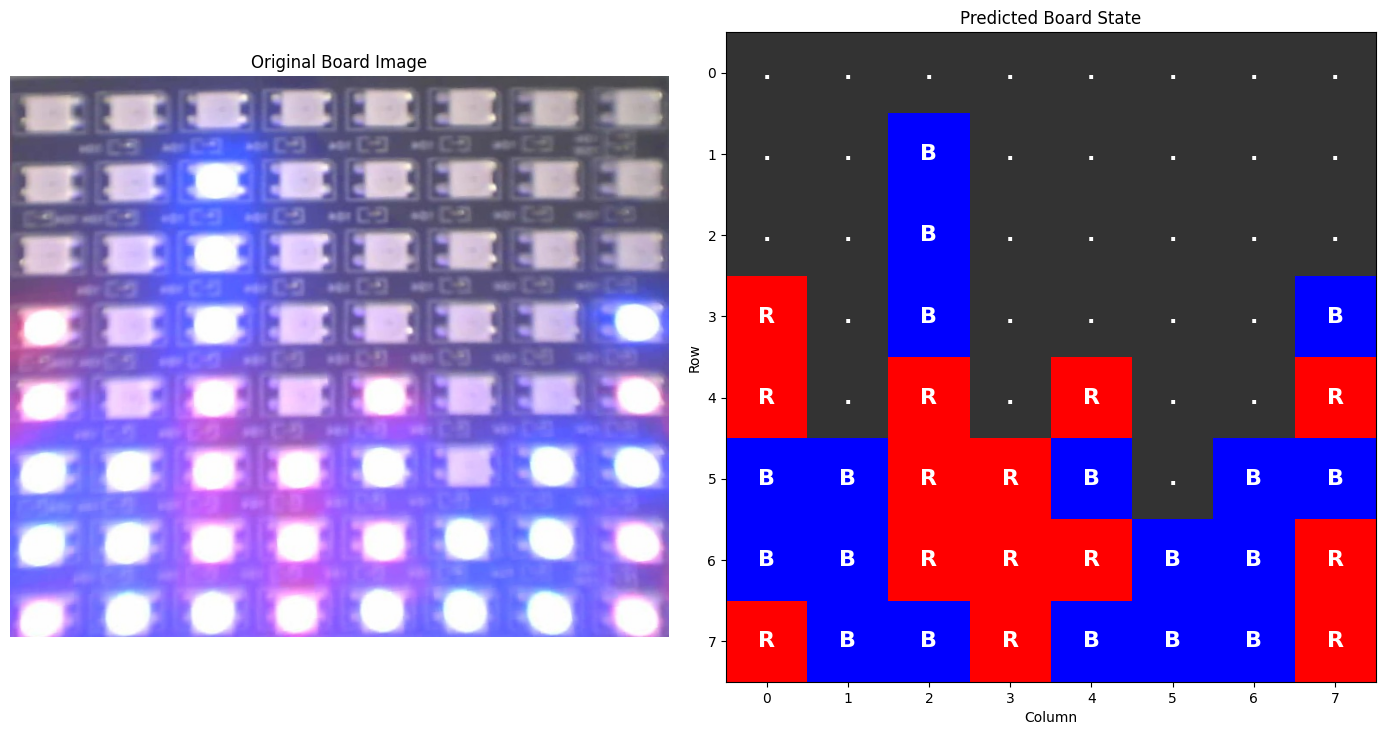


Predicted 64-element array:
[1, 1, 2, 1, 2, 0, 0, 0, 2, 2, 2, 0, 0, 0, 0, 0, 2, 2, 0, 0, 0, 0, 0, 0, 2, 1, 2, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 2, 1, 1, 1, 2, 2, 2, 0, 2, 2, 2, 0, 0, 0, 0, 0, 1, 2, 2, 1, 1, 0, 0, 0]

Grid format (row 0 = top):
Row 0: . . . . . . . .
Row 1: . . B . . . . .
Row 2: . . B . . . . .
Row 3: R . B . . . . B
Row 4: R . R . R . . R
Row 5: B B R R B . B B
Row 6: B B R R R B B R
Row 7: R B B R B B B R


array([1, 1, 2, 1, 2, 0, 0, 0, 2, 2, 2, 0, 0, 0, 0, 0, 2, 2, 0, 0, 0, 0,
       0, 0, 2, 1, 2, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 2, 1, 1, 1,
       2, 2, 2, 0, 2, 2, 2, 0, 0, 0, 0, 0, 1, 2, 2, 1, 1, 0, 0, 0],
      dtype=int64)

In [22]:
# Upload a full board image to test
visualize_board_prediction("cropped_images/photos/1.jpg", model, TILE_SIZE)

## 🔟 Export Model for ESP32

In [23]:
# Save Keras model
model.save('tile_model.keras')
print("Saved: tile_model.keras")

# Convert to TFLite (float32)
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

with open('tile_model.tflite', 'wb') as f:
    f.write(tflite_model)
print(f"Saved: tile_model.tflite ({len(tflite_model)/1024:.1f} KB)")

# Convert to quantized TFLite (int8) - smaller!
def representative_dataset():
    for i in range(min(200, X_train.shape[0])):
        yield [X_train[i:i+1].astype(np.float32)]

try:
    converter_q = tf.lite.TFLiteConverter.from_keras_model(model)
    converter_q.optimizations = [tf.lite.Optimize.DEFAULT]
    converter_q.representative_dataset = representative_dataset
    converter_q.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter_q.inference_input_type = tf.uint8
    converter_q.inference_output_type = tf.uint8
    
    tflite_quant = converter_q.convert()
    
    with open('tile_model_quant.tflite', 'wb') as f:
        f.write(tflite_quant)
    print(f"Saved: tile_model_quant.tflite ({len(tflite_quant)/1024:.1f} KB)")
except Exception as e:
    print(f"Quantization failed: {e}")
    tflite_quant = None

Saved: tile_model.keras
INFO:tensorflow:Assets written to: C:\Users\krist\AppData\Local\Temp\tmp1n25l40a\assets


INFO:tensorflow:Assets written to: C:\Users\krist\AppData\Local\Temp\tmp1n25l40a\assets


Saved: tile_model.tflite (50.7 KB)
INFO:tensorflow:Assets written to: C:\Users\krist\AppData\Local\Temp\tmpn27oeezk\assets


INFO:tensorflow:Assets written to: C:\Users\krist\AppData\Local\Temp\tmpn27oeezk\assets


Saved: tile_model_quant.tflite (21.0 KB)


c:\Users\krist\miniconda3\envs\cis5810-p7\lib\site-packages\tensorflow\lite\python\convert.py:887: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


In [24]:
def convert_to_c_header(tflite_path, header_path, array_name='tile_model'):
    """
    Convert TFLite model to C header file for Arduino.
    """
    with open(tflite_path, 'rb') as f:
        model_bytes = f.read()
    
    # Convert to hex array
    hex_values = ', '.join(f'0x{b:02x}' for b in model_bytes)
    
    # Create header content
    header = f'''// Auto-generated TensorFlow Lite model for LED tile classification
// Model size: {len(model_bytes)} bytes ({len(model_bytes)/1024:.1f} KB)
// Input: {TILE_SIZE}x{TILE_SIZE}x3 (single LED tile)
// Output: 3 classes (Empty=0, Red=1, Blue=2)

#ifndef TILE_MODEL_H
#define TILE_MODEL_H

const unsigned int {array_name}_len = {len(model_bytes)};

alignas(8) const unsigned char {array_name}[] = {{
  {hex_values}
}};

#endif // TILE_MODEL_H
'''
    
    with open(header_path, 'w') as f:
        f.write(header)
    
    print(f"Saved: {header_path}")

# Generate C header files
convert_to_c_header('tile_model.tflite', 'tile_model.h', 'tile_model')

if tflite_quant:
    convert_to_c_header('tile_model_quant.tflite', 'tile_model_quant.h', 'tile_model')

Saved: tile_model.h
Saved: tile_model_quant.h


In [ ]:
# Download all files
print("\nDownloading model files...")

# Create a zip with all outputs
import shutil

output_files = ['tile_model.keras', 'tile_model.tflite', 'tile_model.h']
if os.path.exists('tile_model_quant.tflite'):
    output_files.extend(['tile_model_quant.tflite', 'tile_model_quant.h'])

# Zip all outputs
shutil.make_archive('trained_model', 'zip', '.', '.')

# Download individual files
for f in output_files:
    if os.path.exists(f):
        files.download(f)

print("\n✅ Done! Files downloaded:")
for f in output_files:
    if os.path.exists(f):
        size = os.path.getsize(f)
        print(f"  - {f} ({size/1024:.1f} KB)")

## 📋 Summary

You now have:
1. **tile_model.h** - C header for ESP32 (use this in Arduino)
2. **tile_model.tflite** - TFLite model (float32)
3. **tile_model_quant.tflite** - Quantized model (int8, smaller)

Copy `tile_model.h` to your Arduino sketch folder and use the updated Arduino code!